In [86]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

In [87]:
df=pd.read_csv('DATASET.csv')

In [88]:
df.columns

Index(['S.NO', 'PROP_ID', 'SIZE_OF_PROPERTY', 'NO_OF_BEDROOMS', 'LOCALITY',
       'PROPERTY_TYPE', 'TOTAL_FLOOR', 'AGE_OF_BUILDING', 'PRICE_IN_LAKHS',
       'CONSTRUCTION_STATUS', 'LATITUDE', 'LOGITUDE'],
      dtype='object')

In [89]:
# Drop unnecessary columns
df = df.drop(columns=["S.NO", "PROP_ID"])
df.columns

Index(['SIZE_OF_PROPERTY', 'NO_OF_BEDROOMS', 'LOCALITY', 'PROPERTY_TYPE',
       'TOTAL_FLOOR', 'AGE_OF_BUILDING', 'PRICE_IN_LAKHS',
       'CONSTRUCTION_STATUS', 'LATITUDE', 'LOGITUDE'],
      dtype='object')

In [90]:
print(df.isna().sum())
print(df.shape)

SIZE_OF_PROPERTY       0
NO_OF_BEDROOMS         0
LOCALITY               0
PROPERTY_TYPE          0
TOTAL_FLOOR            1
AGE_OF_BUILDING        0
PRICE_IN_LAKHS         0
CONSTRUCTION_STATUS    0
LATITUDE               0
LOGITUDE               0
dtype: int64
(1000, 10)


In [91]:
df = df.dropna(subset=['TOTAL_FLOOR'])
print(df.isna().sum())
print(df.shape)

SIZE_OF_PROPERTY       0
NO_OF_BEDROOMS         0
LOCALITY               0
PROPERTY_TYPE          0
TOTAL_FLOOR            0
AGE_OF_BUILDING        0
PRICE_IN_LAKHS         0
CONSTRUCTION_STATUS    0
LATITUDE               0
LOGITUDE               0
dtype: int64
(999, 10)


In [92]:
df.dtypes

,0
SIZE_OF_PROPERTY,int64
NO_OF_BEDROOMS,int64
LOCALITY,object
PROPERTY_TYPE,object
TOTAL_FLOOR,float64
AGE_OF_BUILDING,int64
PRICE_IN_LAKHS,float64
CONSTRUCTION_STATUS,object
LATITUDE,float64
LOGITUDE,float64


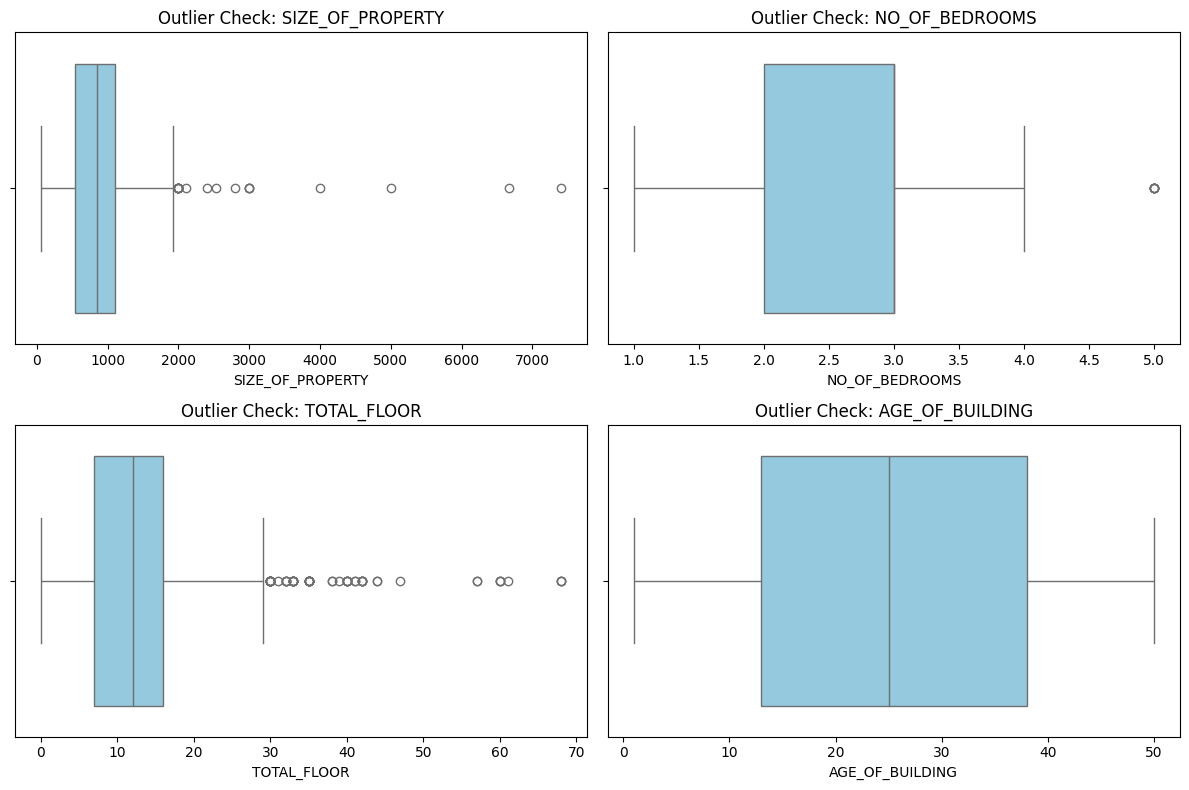

In [93]:
import seaborn as sns
import matplotlib.pyplot as plt

# numerical columns
numerical_cols = ['SIZE_OF_PROPERTY', 'NO_OF_BEDROOMS', 'TOTAL_FLOOR', 'AGE_OF_BUILDING']

# Box plot
plt.figure(figsize=(12, 8))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Outlier Check: {col}')

plt.tight_layout()
plt.show()

In [94]:
# Handling outliers
def handle_outliers(df,columns):
  Q1=df[columns].quantile(0.25)
  Q3=df[columns].quantile(0.75)
  IQR=Q3-Q1
  lower=Q1-(1.5)*IQR
  higher=Q3+(1.5)*IQR

  df=df[((df[columns]>=lower)&(df[columns]<=higher))]
  return df

df=handle_outliers(df,"TOTAL_FLOOR")
df=handle_outliers(df,"PRICE_IN_LAKHS")

Remove extreme outliers using the Interquartile Range (IQR) method
This prevents unusually large properties or floor counts from confusing the model when predicting normal homes

In [95]:
# Encoding(text to number)
text_column=["LOCALITY","PROPERTY_TYPE","CONSTRUCTION_STATUS"]
df=pd.get_dummies(df,columns=text_column,drop_first=True)

In [96]:
# Compress all numerical columns to a similar scale so the model evaluates them fairly
# This prevents large numbers (like 1000 sq ft) from unfairly overpowering small numbers (like 3 bedrooms)
scaler=StandardScaler()
num_column=["SIZE_OF_PROPERTY","NO_OF_BEDROOMS","AGE_OF_BUILDING","TOTAL_FLOOR"]
df[num_column]=scaler.fit_transform(df[num_column])

In [97]:
df.to_csv('cleaned_real_estate_data.csv', index=False)

In [98]:
import pickle
df.to_pickle('cleaned_real_estate_data.pkl')
with open('scaler.pkl', 'wb') as file:
    pickle.dump(scaler, file)

print("Cleaned data and scaler saved successfully!")

Cleaned data and scaler saved successfully!


In [99]:
# To load them back later:
import pandas as pd
import pickle

# Bring the data back
df1 = pd.read_pickle('cleaned_real_estate_data.pkl')

# Bring the scaler back
with open('scaler.pkl', 'rb') as file:
    scaler = pickle.load(file)